# Observatorio Nacional del Mercado Eléctrico Colombiano
## Entrega 3 — Preprocesamiento de la base maestra y definición de KPI

**Introducción a la Analítica de Negocios · Universidad de Antioquia**
**Integrantes:** Juan Esteban Diosa Sanmartín · Juliana Hurtado Mosquera · Daniel Alejandro Osorio

**Insumo:** la base maestra generada con el notebook de la Entrega 2 (versión corregida), con grano nacional-diario para todo 2024 (1 de enero a 31 de diciembre) y llave única `fecha`.

**Preguntas analíticas que guían el preprocesamiento:**
1. ¿Cómo se relaciona el nivel de embalses (disponibilidad hídrica) con el precio de bolsa nacional de energía?
2. ¿Cómo varía la demanda nacional de energía entre días hábiles, fines de semana y festivos?
3. ¿Cómo se relaciona el precio de bolsa con la tasa de cambio (TRM) y con el IPC de energía?

**Orden del preprocesamiento.** Cada paso es una función independiente para que el proceso pueda automatizarse en el mismo batch diario de la Entrega 2. El orden importa:

1. Tipado y unidades.
2. Duplicados (antes de imputar, para no rellenar a partir de filas repetidas).
3. Faltantes.
4. Atípicos: primero se corrigen los errores de la fuente y después se marcan los atípicos reales.
5. Categorización.
6. Estandarización.
7. Cálculo de KPI.

Al final (sección 10) todos los pasos se encadenan en una sola función `preprocesar()`.

## 1. Configuración y carga de datos

La base maestra se lee directamente desde el repositorio del proyecto en GitHub, así que no hay que subir ningún archivo: basta con ejecutar el notebook. Se usa el enlace "raw" del archivo fijado a un commit (`332bbfe`), para que el notebook siempre trabaje sobre la misma base aunque el repositorio cambie después. Si se publica una base actualizada, solo hay que cambiar `URL_BASE_MAESTRA`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (11, 4)

URL_BASE_MAESTRA = ("https://raw.githubusercontent.com/JuanDiosa/AnaliticaE3/"
                    "332bbfee5823dc761aa6a3280fcdea53ed2c4948/base_maestra_energia_colombia.csv")
RUTA_SALIDA = "datos_procesados"
os.makedirs(RUTA_SALIDA, exist_ok=True)


def cargar_base_maestra(url=URL_BASE_MAESTRA):
    base = pd.read_csv(url)
    print(f"Base cargada desde GitHub: {base.shape[0]} filas, {base.shape[1]} columnas")
    return base


base_cruda = cargar_base_maestra()
base_cruda.head()

Base cargada desde GitHub: 366 filas, 7 columnas


,fecha,demanda_gwh,precio_bolsa_cop_kwh,volumen_util_embalses_kwh,trm,tipo_dia,ipc_var_anual_energia
0,2024-01-01,176.27,219.51,"12,161,276,400.00",NaN,Festivo,9.64
1,2024-01-02,206.69,398.21,"12,100,516,400.00",NaN,Día normal,9.64
2,2024-01-03,214.85,459.93,"12,036,493,600.00","3,895.53",Día normal,9.64
3,2024-01-04,219.41,551.38,"11,965,384,500.00","3,914.60",Día normal,9.64
4,2024-01-05,221.28,625.15,"11,885,861,900.00","3,927.64",Día normal,9.64


### 1.1 Perfil inicial

Antes de transformar se revisa el tamaño, los tipos de dato, los nulos y las estadísticas básicas. Este diagnóstico es el que justifica cada decisión de las secciones siguientes.

In [2]:
print("Dimensiones:", base_cruda.shape)
print("\nTipos de dato:")
print(base_cruda.dtypes)
print("\nNulos por columna:")
print(base_cruda.isna().sum())
base_cruda.describe().T

Dimensiones: (366, 7)

Tipos de dato:
fecha                            str
demanda_gwh                  float64
precio_bolsa_cop_kwh         float64
volumen_util_embalses_kwh    float64
trm                          float64
tipo_dia                         str
ipc_var_anual_energia        float64
dtype: object

Nulos por columna:
fecha                          0
demanda_gwh                    0
precio_bolsa_cop_kwh           0
volumen_util_embalses_kwh      0
trm                          128
tipo_dia                       0
ipc_var_anual_energia          0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
demanda_gwh,366.00,227.62,13.77,176.27,221.23,229.83,237.27,250.16
precio_bolsa_cop_kwh,366.00,686.38,553.00,100.49,372.37,576.46,841.35,"7,233.16"
volumen_util_embalses_kwh,366.00,"8,972,027,409.02","1,936,761,213.36","4,958,518,300.00","7,589,934,075.00","9,416,433,450.00","10,314,692,050.00","12,161,276,400.00"
trm,238.00,"4,075.04",193.51,"3,763.43","3,916.92","4,021.84","4,219.78","4,478.21"
ipc_var_anual_energia,366.00,8.77,0.88,6.96,8.18,9.06,9.34,9.77


Dos cosas saltan a la vista en el perfil y se atienden más adelante:

- La **TRM** tiene un número importante de nulos (sección 4).
- El **precio de bolsa** tiene un máximo de más de 7.000 COP/kWh, muy por encima del percentil 75 (sección 5).

## 2. Tipado y unidades

Al leer el CSV, `fecha` queda como texto y `tipo_dia` como cadena. Se convierte `fecha` a `datetime` (necesario para ordenar, detectar huecos en el calendario y agrupar por mes) y se fuerza el tipo numérico en las variables cuantitativas: si una fuente devolviera un texto en una celda numérica, queda como `NaN` y lo trata el paso de faltantes en lugar de romper el pipeline.

En cuanto a unidades:
- `demanda_gwh` ya viene como energía diaria (suma de las 24 horas), con un promedio cercano a 228 GWh/día, coherente con la demanda del SIN.
- `volumen_util_embalses_kwh` viene en kWh, con valores del orden de 10¹⁰. Se expresa en **GWh** (÷ 1.000.000) para que sea legible en tablas y gráficos y quede en la misma unidad de la demanda. No cambia la información.

In [3]:
COLUMNAS_NUMERICAS = ["demanda_gwh", "precio_bolsa_cop_kwh", "volumen_util_embalses_kwh",
                      "trm", "ipc_var_anual_energia"]


def tipar_y_ajustar_unidades(df):
    df = df.copy()
    df["fecha"] = pd.to_datetime(df["fecha"])
    for c in COLUMNAS_NUMERICAS:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["tipo_dia"] = df["tipo_dia"].astype(str).str.strip()
    df["volumen_util_embalses_gwh"] = df["volumen_util_embalses_kwh"] / 1_000_000
    df = df.drop(columns=["volumen_util_embalses_kwh"])
    return df.sort_values("fecha").reset_index(drop=True)


base = tipar_y_ajustar_unidades(base_cruda)
print(base.dtypes)

fecha                        datetime64[us]
demanda_gwh                         float64
precio_bolsa_cop_kwh                float64
trm                                 float64
tipo_dia                                str
ipc_var_anual_energia               float64
volumen_util_embalses_gwh           float64
dtype: object


## 3. Datos duplicados

**Por qué revisar.** La llave de la base es `fecha`: debe haber exactamente una fila por día. Un duplicado puede aparecer si una fuente devuelve dos registros para el mismo día (por ejemplo, la TRM con dos certificaciones, o XM con una reliquidación) y el `merge` los multiplica. Si eso pasa, cualquier promedio o KPI queda sesgado hacia ese día.

Se revisan tres cosas:
- filas completamente idénticas;
- fechas repetidas con valores distintos;
- continuidad del calendario (que no falten días entre la primera y la última fecha, porque un día ausente es un faltante "invisible" que no aparece como `NaN`).

**Estrategia definida (para automatizar):**
- filas idénticas → se elimina la copia;
- misma fecha con valores distintos → se conserva la última ocurrencia, que corresponde al dato más reciente o reliquidado de la fuente;
- días ausentes del calendario → se reinsertan con `NaN` para que los trate el paso de faltantes.

In [4]:
def tratar_duplicados(df, verbose=True):
    n_identicas = df.duplicated().sum()
    df = df.drop_duplicates()
    n_fecha = df.duplicated("fecha").sum()
    df = df.drop_duplicates("fecha", keep="last")

    calendario = pd.DataFrame({"fecha": pd.date_range(df["fecha"].min(), df["fecha"].max(), freq="D")})
    n_huecos = len(calendario) - len(df)
    df = calendario.merge(df, on="fecha", how="left")

    if verbose:
        print(f"Filas idénticas eliminadas:             {n_identicas}")
        print(f"Fechas repetidas con valores distintos: {n_fecha}")
        print(f"Días faltantes en el calendario:        {n_huecos}")
        print(f"Filas resultantes: {len(df)} (una por día)")
    return df


base = tratar_duplicados(base)

Filas idénticas eliminadas:             0
Fechas repetidas con valores distintos: 0
Días faltantes en el calendario:        0
Filas resultantes: 366 (una por día)


**Resultado.** La base no tiene duplicados ni huecos en el calendario: 366 días (2024 es bisiesto), una fila por día. Era lo esperado, porque en la Entrega 2 la base se construyó partiendo de un calendario completo y cada fuente se unió con `left join` por fecha. Aun así el paso se mantiene en el pipeline, porque protege la base cuando cambie el rango o alguna fuente.

## 4. Datos faltantes

### 4.1 Diagnóstico

In [5]:
faltantes = base.isna().sum().to_frame("nulos")
faltantes["%"] = faltantes["nulos"] / len(base) * 100
faltantes

,nulos,%
fecha,0,0.00
demanda_gwh,0,0.00
precio_bolsa_cop_kwh,0,0.00
trm,128,34.97
tipo_dia,0,0.00
ipc_var_anual_energia,0,0.00
volumen_util_embalses_gwh,0,0.00


La única variable con faltantes es la **TRM** (alrededor de un tercio de los días). Antes de decidir cómo tratarlos hay que entender si son aleatorios o si siguen un patrón.

In [6]:
DIAS_ES = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"}

trm_nula = base[base["trm"].isna()].copy()
trm_nula["dia_semana"] = pd.Categorical(trm_nula["fecha"].dt.dayofweek.map(DIAS_ES),
                                        categories=list(DIAS_ES.values()), ordered=True)
pd.crosstab(trm_nula["dia_semana"], trm_nula["tipo_dia"], margins=True, margins_name="Total")

tipo_dia,Día normal,Festivo,Fin de semana,Total
dia_semana,,,,
Lunes,42,11,0,53
Martes,15,0,0,15
Jueves,4,0,0,4
Viernes,2,1,0,3
Sábado,0,0,1,1
Domingo,0,1,51,52
Total,63,13,52,128


### 4.2 Por qué faltan

El patrón no es aleatorio: casi todos los nulos caen en **domingos, lunes, el día siguiente a un festivo y los festivos**. Esto se explica por cómo se publica la TRM en el dataset de datos.gov.co:

- La Superintendencia Financiera certifica la TRM los días hábiles, y cada certificación tiene un periodo de **vigencia** (`vigenciadesde` – `vigenciahasta`).
- La TRM que se certifica el viernes queda registrada con vigencia desde el sábado y cubre sábado, domingo y lunes (y el martes, si el lunes es festivo). En el dataset solo aparece **una fila**, fechada al inicio de la vigencia.
- La extracción de la Entrega 2 toma solo la fecha de inicio de vigencia, así que los demás días del periodo quedan vacíos.

Es decir, el dato **sí existe** para esos días: es el último valor certificado. No es un faltante real sino un efecto de cómo se publica la serie.

Quedan unos pocos jueves y viernes sin TRM que no encajan en ese patrón (6 en el año). Son días en los que el dataset simplemente no trae registro; para ellos el arrastre del día anterior es una aproximación, no el valor oficial, pero la TRM rara vez cambia más de 1 % de un día a otro.

### 4.3 Estrategia

| Caso | Estrategia | Justificación |
|---|---|---|
| Días dentro de la vigencia de una TRM ya publicada | **Arrastre hacia adelante (`ffill`)** | Replica la regla oficial: la TRM vigente en un día sin certificación es la última certificada. No se inventa información. |
| Primeros días del rango (1 y 2 de enero), sin TRM previa en la base | **Arrastre hacia atrás (`bfill`)** con el primer valor disponible, marcado como imputado | La TRM vigente esos días se certificó en diciembre de 2023, fuera del rango extraído. Es una aproximación; la diferencia con el valor real es pequeña frente a la variabilidad anual de la serie. |
| Variables de XM (demanda, precio, embalses) si falta un día, o si un valor se anula por ser un error (sección 5) | **Interpolación lineal**, máximo 3 días seguidos | Son series físicas continuas; un hueco corto se aproxima bien con los vecinos. Un hueco mayor debe revisarse en la fuente, no rellenarse. |
| IPC de energía si falta un mes | Arrastre del último mes publicado | El DANE publica con rezago; el último dato publicado es el vigente. |

Se descartó **eliminar filas**: perder un tercio de los días (justamente fines de semana y festivos) haría imposible responder la pregunta 2. También se descartó **imputar con la media**, porque la TRM tuvo una tendencia marcada en 2024 y la media del año no representa a ningún día concreto.

Se agrega la columna `trm_imputada` para que quede trazable qué valores fueron completados.

**Recomendación para automatizar:** en la extracción, pedir la TRM desde 7 días antes de `FECHA_INICIO` y propagar cada valor entre `vigenciadesde` y `vigenciahasta`. Con eso desaparece incluso el `bfill` de los primeros días.

In [7]:
MAX_DIAS_INTERPOLAR = 3
VARIABLES_XM = ["demanda_gwh", "precio_bolsa_cop_kwh", "volumen_util_embalses_gwh"]


def interpolar_xm(df):
    df = df.copy()
    for c in VARIABLES_XM:
        df[c] = df[c].interpolate(method="linear", limit=MAX_DIAS_INTERPOLAR, limit_area="inside")
    return df


def tratar_faltantes(df, verbose=True):
    df = df.copy()
    df["trm_imputada"] = df["trm"].isna()
    df["trm"] = df["trm"].ffill().bfill()
    df = interpolar_xm(df)
    df["ipc_var_anual_energia"] = df["ipc_var_anual_energia"].ffill()

    if verbose:
        print(f"TRM imputada en {df['trm_imputada'].sum()} días.")
        print("\nNulos restantes:")
        print(df.isna().sum())
    return df


base = tratar_faltantes(base)

TRM imputada en 128 días.

Nulos restantes:
fecha                        0
demanda_gwh                  0
precio_bolsa_cop_kwh         0
trm                          0
tipo_dia                     0
ipc_var_anual_energia        0
volumen_util_embalses_gwh    0
trm_imputada                 0
dtype: int64


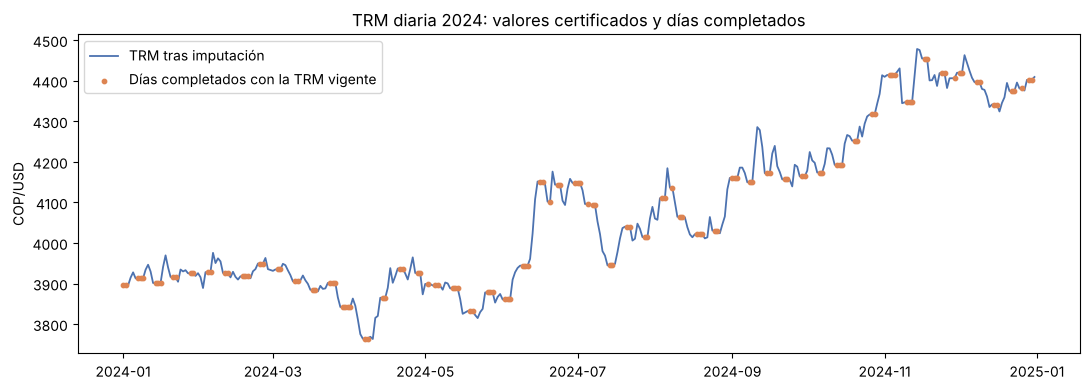

In [8]:
fig, ax = plt.subplots()
ax.plot(base["fecha"], base["trm"], color="#4C72B0", lw=1.3, label="TRM tras imputación")
ax.scatter(base.loc[base["trm_imputada"], "fecha"], base.loc[base["trm_imputada"], "trm"],
           color="#DD8452", s=10, zorder=3, label="Días completados con la TRM vigente")
ax.set_title("TRM diaria 2024: valores certificados y días completados")
ax.set_ylabel("COP/USD")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Datos atípicos

En esta base hay que distinguir dos tipos de valores extremos, porque se tratan de forma opuesta:

- **Errores de la fuente:** valores que no pueden ser reales (por ejemplo, un precio que se multiplica varias veces de un día a otro y vuelve al nivel normal al día siguiente). Distorsionan cualquier promedio o correlación, así que se **corrigen**.
- **Atípicos reales:** valores extremos pero explicables por lo que pasó en el mercado (El Niño, temporada de lluvias, festivos). Son justamente la señal que el observatorio quiere monitorear, así que se **conservan y se marcan**.

### 5.1 Errores de la fuente

Se aplican dos reglas:

1. **Rango físico.** Valores fuera de un rango posible (precio negativo, demanda cero, TRM absurda).
2. **Salto aislado.** Un valor que es más de 3 veces (o menos de un tercio) la **mediana móvil centrada de 7 días**. La mediana no se deja arrastrar por el propio valor extremo, y la regla solo se dispara con picos de un día que no tienen continuidad. Un alza sostenida, como la de octubre, sube también la mediana y no queda marcada.

Los valores detectados se convierten en `NaN` y se completan con la interpolación de la sección 4. Se deja la columna `precio_corregido` para trazabilidad.

In [9]:
REGLAS_RANGO_FISICO = {
    "demanda_gwh": (50, 400),             # GWh/día del SIN
    "precio_bolsa_cop_kwh": (0, 10000),   # COP/kWh
    "volumen_util_embalses_gwh": (0, 25000),
    "trm": (1000, 10000),
}
UMBRAL_SALTO = 3          # veces la mediana móvil
VENTANA_MEDIANA = 7       # días


def detectar_errores(df):
    errores = pd.DataFrame(False, index=df.index, columns=VARIABLES_XM + ["trm"])
    for col, (minimo, maximo) in REGLAS_RANGO_FISICO.items():
        errores[col] |= ~df[col].between(minimo, maximo)
    for col in VARIABLES_XM:
        mediana = df[col].rolling(VENTANA_MEDIANA, center=True, min_periods=3).median()
        razon = df[col] / mediana
        errores[col] |= (razon > UMBRAL_SALTO) | (razon < 1 / UMBRAL_SALTO)
    return errores


def corregir_errores(df, verbose=True):
    df = df.copy()
    errores = detectar_errores(df)
    if verbose:
        print("Valores identificados como error de la fuente:")
        print(errores.sum())
        filas = errores.any(axis=1)
        if filas.any():
            print("\nDetalle (valor original):")
            print(df.loc[filas, ["fecha"] + [c for c in errores.columns if errores.loc[filas, c].any()]])
    df["precio_corregido"] = errores["precio_bolsa_cop_kwh"]
    for col in errores.columns:
        df.loc[errores[col], col] = np.nan
    df = interpolar_xm(df)
    df["trm"] = df["trm"].ffill().bfill()
    return df


base = corregir_errores(base)
print("\nPrecio alrededor del 30 de septiembre después de la corrección:")
print(base.loc[base["fecha"].between("2024-09-27", "2024-10-03"), ["fecha", "precio_bolsa_cop_kwh", "precio_corregido"]])

Valores identificados como error de la fuente:
demanda_gwh                  0
precio_bolsa_cop_kwh         1
volumen_util_embalses_gwh    0
trm                          0
dtype: int64

Detalle (valor original):
         fecha  precio_bolsa_cop_kwh
273 2024-09-30              7,233.16

Precio alrededor del 30 de septiembre después de la corrección:
         fecha  precio_bolsa_cop_kwh  precio_corregido
270 2024-09-27                909.50             False
271 2024-09-28                911.63             False
272 2024-09-29                911.06             False
273 2024-09-30                989.52              True
274 2024-10-01              1,067.98             False
275 2024-10-02              1,147.15             False
276 2024-10-03              1,457.06             False


**Resultado.** La regla solo encuentra un caso: el precio de bolsa del **30 de septiembre de 2024** (7.233 COP/kWh), unas 7 veces la mediana de los días vecinos (alrededor de 920 COP/kWh), que vuelve a su nivel el 1 de octubre. Además el valor llega con tres decimales exactos, a diferencia del resto de la serie, que es un promedio de 24 valores horarios. Todo apunta a un error en el registro de ese día y no a un evento del mercado. Se reemplaza por la interpolación entre el 29 de septiembre y el 1 de octubre.

### 5.2 Atípicos reales: detección

Sobre la serie ya corregida se usa el **rango intercuartílico (IQR)**: un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR. Se prefirió frente al z-score porque no asume normalidad, y el precio de bolsa tiene una distribución asimétrica con cola larga a la derecha.

- Para la **demanda**, el IQR se calcula **dentro de cada tipo de día**. Si se calculara sobre todo el año, los festivos y domingos aparecerían como atípicos solo por ser días de menor consumo, cuando precisamente esa diferencia es la que se mide en la pregunta 2.
- Para los **embalses** no se evalúa el nivel (es una serie con tendencia y estacionalidad, y el IQR no aplica bien), sino el **cambio diario**, con un umbral más amplio (3·IQR) para marcar solo los movimientos extraordinarios.
- El IPC no se evalúa: es mensual y solo tiene 12 valores.

In [10]:
def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def marcar_atipicos(df):
    df = df.copy()

    li, ls = limites_iqr(df["precio_bolsa_cop_kwh"])
    df["atipico_precio"] = ~df["precio_bolsa_cop_kwh"].between(li, ls)

    li, ls = limites_iqr(df["trm"])
    df["atipico_trm"] = ~df["trm"].between(li, ls)

    df["atipico_demanda"] = False
    for _, grupo in df.groupby("tipo_dia"):
        li, ls = limites_iqr(grupo["demanda_gwh"])
        df.loc[grupo.index, "atipico_demanda"] = ~grupo["demanda_gwh"].between(li, ls)

    cambio_embalse = df["volumen_util_embalses_gwh"].diff()
    li, ls = limites_iqr(cambio_embalse.dropna(), k=3)
    df["atipico_embalse"] = ~cambio_embalse.between(li, ls) & cambio_embalse.notna()
    return df


base = marcar_atipicos(base)
COLS_ATIPICO = ["atipico_precio", "atipico_trm", "atipico_demanda", "atipico_embalse"]
print("Atípicos marcados por variable:")
print(base[COLS_ATIPICO].sum())
print("\nAtípicos de precio por mes:")
print(base.loc[base["atipico_precio"], "fecha"].dt.to_period("M").value_counts().sort_index())

Atípicos marcados por variable:
atipico_precio     22
atipico_trm         0
atipico_demanda     3
atipico_embalse     1
dtype: int64

Atípicos de precio por mes:
fecha
2024-10    15
2024-11     7
Freq: M, Name: count, dtype: int64


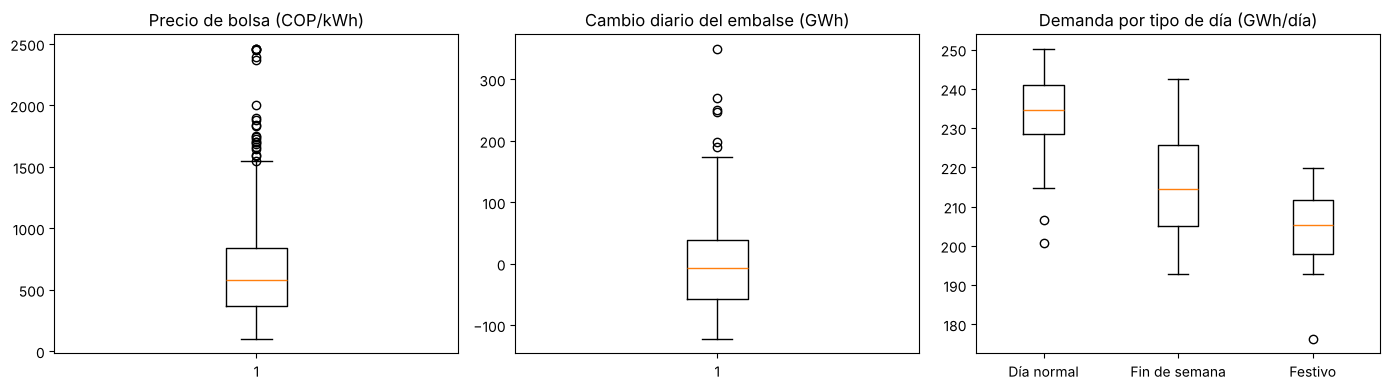

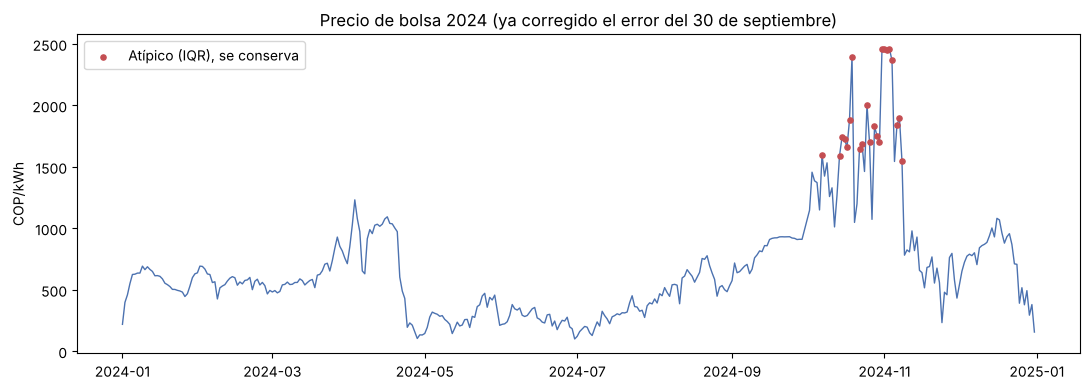

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].boxplot(base["precio_bolsa_cop_kwh"])
axes[0].set_title("Precio de bolsa (COP/kWh)")
axes[1].boxplot(base["volumen_util_embalses_gwh"].diff().dropna())
axes[1].set_title("Cambio diario del embalse (GWh)")
orden = ["Día normal", "Fin de semana", "Festivo"]
axes[2].boxplot([base.loc[base["tipo_dia"] == t, "demanda_gwh"] for t in orden])
axes[2].set_xticks([1, 2, 3], orden)
axes[2].set_title("Demanda por tipo de día (GWh/día)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(base["fecha"], base["precio_bolsa_cop_kwh"], color="#4C72B0", lw=1)
ax.scatter(base.loc[base["atipico_precio"], "fecha"], base.loc[base["atipico_precio"], "precio_bolsa_cop_kwh"],
           color="#C44E52", s=14, zorder=3, label="Atípico (IQR), se conserva")
ax.set_title("Precio de bolsa 2024 (ya corregido el error del 30 de septiembre)")
ax.set_ylabel("COP/kWh")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
base.loc[base["atipico_demanda"] | base["atipico_embalse"] | base["atipico_trm"],
         ["fecha", "tipo_dia", "demanda_gwh", "volumen_util_embalses_gwh", "trm"] + COLS_ATIPICO[1:]]

,fecha,tipo_dia,demanda_gwh,volumen_util_embalses_gwh,trm,atipico_trm,atipico_demanda,atipico_embalse
0,2024-01-01,Festivo,176.27,"12,161.28","3,895.53",False,True,False
1,2024-01-02,Día normal,206.69,"12,100.52","3,895.53",False,True,False
167,2024-06-16,Fin de semana,193.08,"9,166.26","4,151.55",False,False,True
365,2024-12-31,Día normal,200.83,"11,678.42","4,409.15",False,True,False


### 5.3 Estrategia: conservar y marcar

Revisando los días señalados, ninguno corresponde a un error de medición:

- **Precio de bolsa (22 días).** Todos caen en **octubre y noviembre de 2024**, cuando el precio superó los 1.500 COP/kWh durante varias semanas por la caída de los aportes hídricos y el mayor despacho térmico. Entre el 31 de octubre y el 3 de noviembre el precio se queda prácticamente fijo en ≈2.459,5 COP/kWh, lo que es consistente con un precio que toca un tope regulatorio, no con un error de captura. Es el episodio más importante del año para las preguntas 1 y 3.
- **Demanda (3 días).** El 1 y 2 de enero y el 31 de diciembre: Año Nuevo, el regreso lento de vacaciones y la víspera de Año Nuevo tienen un consumo bajo incluso para su categoría.
- **Embalses (1 día).** El 16 de junio el volumen útil subió unos 350 GWh en un día, el mayor aumento del año, por aportes de lluvia concentrados.
- **TRM (0 días).** La devaluación del segundo semestre fue gradual, sin saltos que el IQR marque.

Por eso **no se eliminan ni se reemplazan**: hacerlo borraría la señal que el observatorio quiere monitorear. Las columnas booleanas `atipico_*` permiten filtrarlos si un análisis concreto lo requiere (por ejemplo, un modelo sensible a extremos).

## 6. Categorización de variables

**¿Hace falta categorizar?** Sí, en tres casos, cada uno ligado a una pregunta analítica:

| Variable nueva | Origen | Por qué | Pregunta |
|---|---|---|---|
| `tipo_dia` como categoría ordenada | Ya existe como texto | Como texto, pandas acepta cualquier valor. Como categoría se garantiza que solo existan los tres valores válidos y un orden fijo en tablas y gráficos. Se crean además variables dummy para usos futuros (modelos). | 2 |
| `nivel_embalse` (Bajo / Medio / Alto) | `volumen_util_embalses_gwh` | Comparar el precio promedio según el nivel de embalse es más directo para el usuario que una nube de puntos. Se usan terciles del año para que cada grupo tenga un número similar de días. | 1 |
| `mes` y `dia_semana` | `fecha` | El IPC es mensual y los KPI se reportan por mes; el día de la semana permite ver si el efecto "fin de semana" es del sábado, del domingo o de ambos. | 2 y 3 |

No se categorizan el precio ni la TRM: discretizarlos perdería información y las preguntas piden relacionarlos de forma continua.

Nota: los terciles se recalculan con cada carga, así que "Bajo" significa bajo **en relación con el periodo analizado**. Si el observatorio acumula varios años, conviene fijar los cortes con base en el porcentaje de la capacidad útil del SIN, que XM publica como métrica aparte.

In [13]:
ORDEN_TIPO_DIA = ["Día normal", "Fin de semana", "Festivo"]


def categorizar(df):
    df = df.copy()
    df["tipo_dia"] = pd.Categorical(df["tipo_dia"], categories=ORDEN_TIPO_DIA, ordered=True)
    df["nivel_embalse"] = pd.qcut(df["volumen_util_embalses_gwh"], q=3, labels=["Bajo", "Medio", "Alto"])
    df["mes"] = df["fecha"].dt.to_period("M").astype(str)
    df["dia_semana"] = pd.Categorical(df["fecha"].dt.dayofweek.map(DIAS_ES),
                                      categories=list(DIAS_ES.values()), ordered=True)
    dummies = pd.get_dummies(df["tipo_dia"], prefix="dia", dtype=int)
    dummies.columns = ["dia_normal", "dia_fin_de_semana", "dia_festivo"]
    return pd.concat([df, dummies], axis=1)


base = categorizar(base)
print(base["tipo_dia"].value_counts().sort_index())
print()
print(base.groupby("nivel_embalse", observed=True)["volumen_util_embalses_gwh"].agg(["min", "max", "count"]))

tipo_dia
Día normal       246
Fin de semana    102
Festivo           18
Name: count, dtype: int64

                    min       max  count
nivel_embalse                           
Bajo           4,958.52  8,626.40    122
Medio          8,631.80 10,083.82    122
Alto          10,085.64 12,161.28    122


## 7. Normalización / estandarización

**¿Hace falta?** Las variables tienen escalas muy distintas: la demanda está alrededor de 230 GWh/día, el precio entre 100 y 2.500 COP/kWh, los embalses entre 5.000 y 12.000 GWh, la TRM entre 3.700 y 4.500 y el IPC entre 7 % y 10 %.

- Para los **KPI no se estandariza**: deben leerse en sus unidades originales (COP/kWh, GWh, USD/MWh), que son las que entiende el usuario del observatorio.
- Para **correlaciones** tampoco hace falta: el coeficiente de Pearson ya es invariante a la escala.
- **Sí hace falta** para dos usos: (1) graficar varias series en un mismo eje y comparar su movimiento conjunto (preguntas 1 y 3), y (2) dejar la base lista para modelos que dependen de distancias o de la magnitud de los coeficientes (regresión regularizada, clustering).

Se elige **estandarización z-score** (media 0, desviación 1) en lugar de min-max porque el precio tiene valores extremos que se decidió conservar: con min-max, las semanas de octubre comprimirían el resto del año en un rango muy pequeño. Las columnas estandarizadas se agregan con el sufijo `_z` y **no reemplazan** las originales.

El IPC no se estandariza: con un valor por mes no aporta variación útil a la escala diaria.

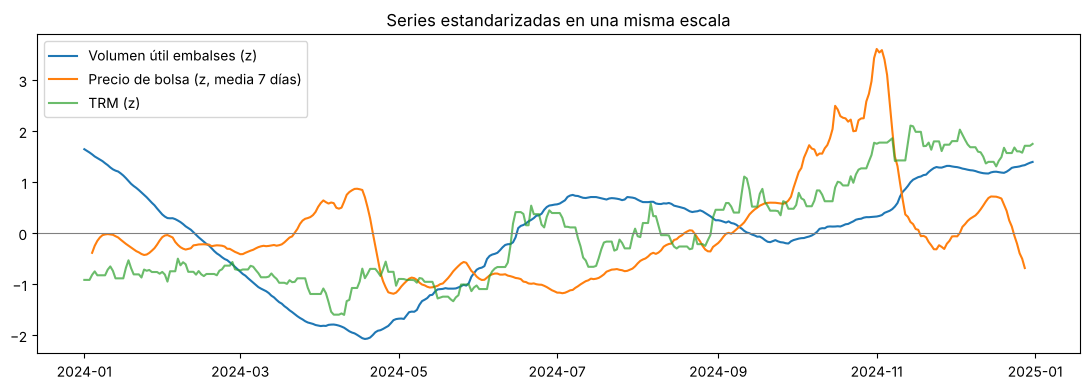

In [14]:
COLUMNAS_A_ESTANDARIZAR = ["demanda_gwh", "precio_bolsa_cop_kwh", "volumen_util_embalses_gwh", "trm"]


def estandarizar(df):
    df = df.copy()
    for c in COLUMNAS_A_ESTANDARIZAR:
        df[f"{c}_z"] = (df[c] - df[c].mean()) / df[c].std()
    return df


base = estandarizar(base)

fig, ax = plt.subplots()
ax.plot(base["fecha"], base["volumen_util_embalses_gwh_z"], label="Volumen útil embalses (z)")
ax.plot(base["fecha"], base["precio_bolsa_cop_kwh_z"].rolling(7, center=True).mean(), label="Precio de bolsa (z, media 7 días)")
ax.plot(base["fecha"], base["trm_z"], label="TRM (z)", alpha=0.7)
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Series estandarizadas en una misma escala")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Base analítica final

Se exporta la base preprocesada en `.parquet` (conserva tipos y categorías) y `.csv`.

In [15]:
ORDEN_COLUMNAS = [
    "fecha", "mes", "dia_semana", "tipo_dia", "dia_normal", "dia_fin_de_semana", "dia_festivo",
    "demanda_gwh", "precio_bolsa_cop_kwh", "precio_corregido", "volumen_util_embalses_gwh", "nivel_embalse",
    "trm", "trm_imputada", "ipc_var_anual_energia",
    "atipico_precio", "atipico_trm", "atipico_demanda", "atipico_embalse",
    "demanda_gwh_z", "precio_bolsa_cop_kwh_z", "volumen_util_embalses_gwh_z", "trm_z",
]
base_analitica = base[ORDEN_COLUMNAS]
base_analitica.to_parquet(f"{RUTA_SALIDA}/base_analitica_energia_colombia.parquet", index=False)
base_analitica.to_csv(f"{RUTA_SALIDA}/base_analitica_energia_colombia.csv", index=False)
print(base_analitica.shape)
base_analitica.head()

(366, 23)


,fecha,mes,dia_semana,tipo_dia,dia_normal,dia_fin_de_semana,dia_festivo,demanda_gwh,precio_bolsa_cop_kwh,precio_corregido,...,trm_imputada,ipc_var_anual_energia,atipico_precio,atipico_trm,atipico_demanda,atipico_embalse,demanda_gwh_z,precio_bolsa_cop_kwh_z,volumen_util_embalses_gwh_z,trm_z
0,2024-01-01,2024-01,Lunes,Festivo,0,0,1,176.27,219.51,False,...,True,9.64,False,False,True,False,-3.73,-1.04,1.65,-0.91
1,2024-01-02,2024-01,Martes,Día normal,1,0,0,206.69,398.21,False,...,True,9.64,False,False,True,False,-1.52,-0.62,1.62,-0.91
2,2024-01-03,2024-01,Miércoles,Día normal,1,0,0,214.85,459.93,False,...,False,9.64,False,False,False,False,-0.93,-0.48,1.58,-0.91
3,2024-01-04,2024-01,Jueves,Día normal,1,0,0,219.41,551.38,False,...,False,9.64,False,False,False,False,-0.60,-0.27,1.55,-0.82
4,2024-01-05,2024-01,Viernes,Día normal,1,0,0,221.28,625.15,False,...,False,9.64,False,False,False,False,-0.46,-0.10,1.50,-0.75


## 9. Indicadores (KPI)

Se definen tres indicadores, uno por pregunta analítica. Todos se calculan con funciones a partir de la base analítica, así que se actualizan solos cada vez que corre el pipeline.

### KPI 1 — Correlación móvil embalse–precio (pregunta 1)

| Elemento | Descripción |
|---|---|
| **Definición** | Grado de asociación lineal entre el volumen útil de los embalses y el precio de bolsa en los últimos 30 días. |
| **Fórmula** | $\rho_t = \text{corr}\big(\text{Vol}_{t-29..t},\ \text{Precio}_{t-29..t}\big)$ (Pearson, ventana móvil de 30 días) |
| **Unidad** | Coeficiente adimensional entre −1 y 1. |
| **Interpretación** | Cerca de −1: el precio está respondiendo a la escasez hídrica (cuando el embalse baja, el precio sube). Cerca de 0: el precio lo están moviendo otros factores (demanda, combustibles, restricciones). Valores positivos sostenidos indican que ambas series se mueven por causas distintas en ese periodo. |
| **Periodicidad** | Diaria (se recalcula con cada dato nuevo); se reporta el cierre de cada mes. |
| **Relevancia** | Le dice a generadores y comercializadores si el nivel de embalses es hoy una buena señal para anticipar el precio, y a planeadores en qué momentos el sistema se vuelve más dependiente de la hidrología. |

Como apoyo, se calcula también el **precio promedio por nivel de embalse** (Bajo / Medio / Alto).

In [16]:
VENTANA_KPI1 = 30


def kpi_correlacion_embalse_precio(df, ventana=VENTANA_KPI1):
    serie = (df.set_index("fecha")["volumen_util_embalses_gwh"]
               .rolling(ventana, min_periods=ventana)
               .corr(df.set_index("fecha")["precio_bolsa_cop_kwh"]))
    diario = serie.rename("kpi1_corr_embalse_precio").reset_index()
    cierre_mes = (diario.dropna().assign(mes=lambda d: d["fecha"].dt.to_period("M").astype(str))
                        .groupby("mes").last()[["kpi1_corr_embalse_precio"]])
    precio_por_nivel = (df.groupby("nivel_embalse", observed=True)
                          .agg(volumen_promedio_gwh=("volumen_util_embalses_gwh", "mean"),
                               precio_promedio_cop_kwh=("precio_bolsa_cop_kwh", "mean"),
                               precio_mediano_cop_kwh=("precio_bolsa_cop_kwh", "median"),
                               dias=("fecha", "count")))
    return diario, cierre_mes, precio_por_nivel


kpi1_diario, kpi1_mes, kpi1_nivel = kpi_correlacion_embalse_precio(base_analitica)
print(f"Correlación embalse–precio en todo el año: "
      f"{base_analitica['volumen_util_embalses_gwh'].corr(base_analitica['precio_bolsa_cop_kwh']):.2f}\n")
print("KPI 1 al cierre de cada mes:")
print(kpi1_mes)
print("\nPrecio por nivel de embalse:")
kpi1_nivel

Correlación embalse–precio en todo el año: 0.04

KPI 1 al cierre de cada mes:
         kpi1_corr_embalse_precio
mes                              
2024-01                      0.23
2024-02                      0.49
2024-03                     -0.86
2024-04                     -0.46
2024-05                      0.31
2024-06                     -0.54
2024-07                     -0.11
2024-08                     -0.26
2024-09                     -0.95
2024-10                      0.42
2024-11                     -0.89
2024-12                     -0.93

Precio por nivel de embalse:


,volumen_promedio_gwh,precio_promedio_cop_kwh,precio_mediano_cop_kwh,dias
nivel_embalse,,,,
Bajo,"6,624.74",531.59,509.76,122
Medio,"9,373.44",927.12,712.89,122
Alto,"10,917.91",549.25,533.95,122


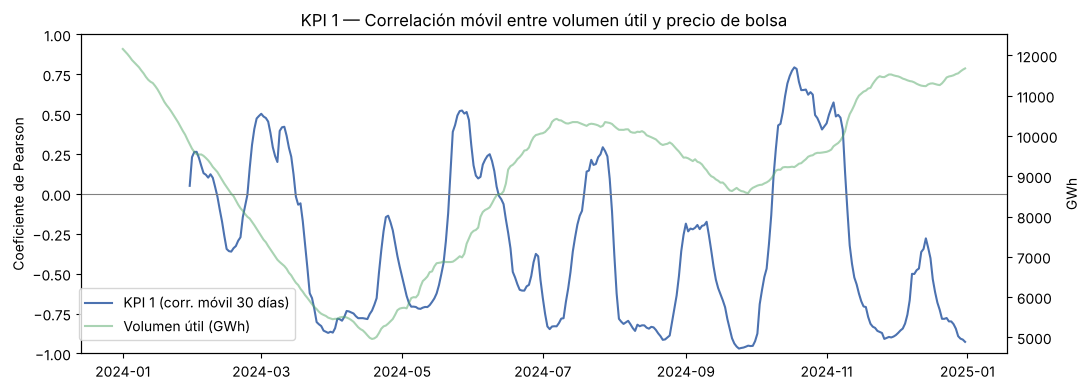

In [17]:
fig, ax1 = plt.subplots()
ax1.plot(kpi1_diario["fecha"], kpi1_diario["kpi1_corr_embalse_precio"], color="#4C72B0", label="KPI 1 (corr. móvil 30 días)")
ax1.axhline(0, color="grey", lw=0.8)
ax1.set_ylim(-1, 1)
ax1.set_ylabel("Coeficiente de Pearson")
ax2 = ax1.twinx()
ax2.plot(base_analitica["fecha"], base_analitica["volumen_util_embalses_gwh"], color="#55A868", alpha=0.5, label="Volumen útil (GWh)")
ax2.set_ylabel("GWh")
ax1.set_title("KPI 1 — Correlación móvil entre volumen útil y precio de bolsa")
fig.legend(loc="lower left", bbox_to_anchor=(0.07, 0.12))
plt.tight_layout()
plt.show()

### KPI 2 — Índice de demanda relativa por tipo de día (pregunta 2)

| Elemento | Descripción |
|---|---|
| **Definición** | Demanda promedio de cada tipo de día expresada como porcentaje de la demanda promedio de los días normales (hábiles) del mismo mes. |
| **Fórmula** | $\text{IDR}_{k,m} = \dfrac{\overline{D}_{k,m}}{\overline{D}_{\text{Día normal},m}} \times 100$, con $k \in$ {Fin de semana, Festivo} y $m$ = mes |
| **Unidad** | Porcentaje (%). El día normal vale 100 por construcción. |
| **Interpretación** | Un festivo con IDR = 85 consume 15 % menos que un día hábil. Si el índice de los fines de semana sube con el tiempo, el consumo se está volviendo menos dependiente de la actividad laboral (más peso residencial o de industria continua). |
| **Periodicidad** | Mensual. Los meses sin festivos quedan vacíos en esa categoría; por eso se reporta también el valor anual. |
| **Relevancia** | Los comercializadores ajustan sus compras de energía y el operador su despacho según el tipo de día; medir la caída en porcentaje y no en GWh permite comparar meses con distinto nivel de demanda. |

In [18]:
def kpi_demanda_relativa(df):
    prom = df.groupby(["mes", "tipo_dia"], observed=False)["demanda_gwh"].mean().unstack()
    idr = prom.div(prom["Día normal"], axis=0) * 100
    total = df.groupby("tipo_dia", observed=False)["demanda_gwh"].mean()
    idr.loc["Año 2024"] = total / total["Día normal"] * 100
    return prom, idr.round(1)


kpi2_promedios, kpi2 = kpi_demanda_relativa(base_analitica)
print("Demanda promedio (GWh/día):")
print(kpi2_promedios.round(1))
print("\nKPI 2 — Índice de demanda relativa (Día normal = 100):")
kpi2

Demanda promedio (GWh/día):
tipo_dia  Día normal  Fin de semana  Festivo
mes                                         
2024-01       231.10         213.50   188.40
2024-02       231.40         212.50      NaN
2024-03       241.90         219.50   207.40
2024-04       233.10         214.10      NaN
2024-05       230.60         213.00   212.20
2024-06       226.00         208.00   204.20
2024-07       232.30         210.10   205.10
2024-08       241.30         220.90   218.50
2024-09       242.90         222.30      NaN
2024-10       231.70         215.00   205.60
2024-11       233.50         212.30   196.50
2024-12       237.90         220.80   202.70

KPI 2 — Índice de demanda relativa (Día normal = 100):


tipo_dia,Día normal,Fin de semana,Festivo
mes,,,
2024-01,100.00,92.40,81.50
2024-02,100.00,91.80,NaN
2024-03,100.00,90.80,85.70
2024-04,100.00,91.80,NaN
2024-05,100.00,92.40,92.00
2024-06,100.00,92.10,90.40
2024-07,100.00,90.50,88.30
2024-08,100.00,91.50,90.60
2024-09,100.00,91.50,NaN


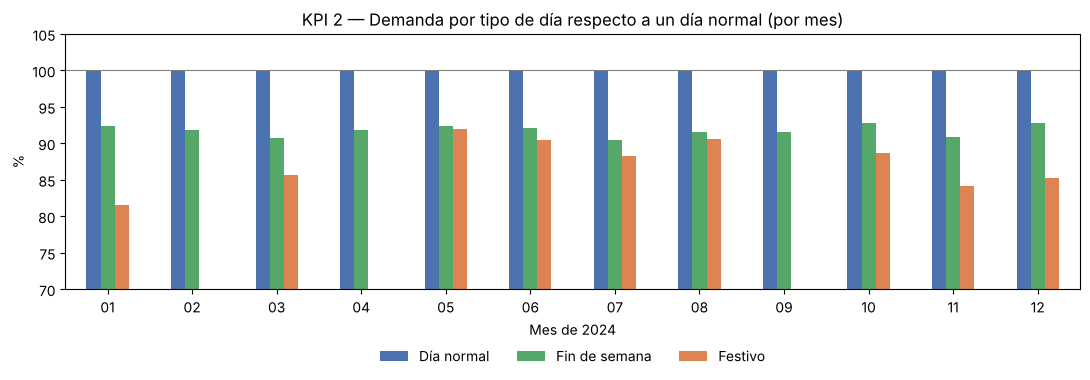

In [19]:
fig, ax = plt.subplots()
kpi2.drop(index="Año 2024").plot(kind="bar", ax=ax, rot=0, color=["#4C72B0", "#55A868", "#DD8452"])
ax.axhline(100, color="grey", lw=0.8)
ax.set_ylim(70, 105)
ax.set_title("KPI 2 — Demanda por tipo de día respecto a un día normal (por mes)")
ax.set_ylabel("%")
ax.set_xticklabels([m[-2:] for m in kpi2.index[:-1]])
ax.set_xlabel("Mes de 2024")
ax.legend(title=None, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.show()

### KPI 3 — Precio de bolsa en dólares (pregunta 3)

| Elemento | Descripción |
|---|---|
| **Definición** | Precio de bolsa nacional convertido a dólares con la TRM vigente del día. |
| **Fórmula** | $P^{USD}_t = \dfrac{P^{COP}_t \times 1000}{\text{TRM}_t}$  (COP/kWh × 1000 = COP/MWh; ÷ TRM = USD/MWh) |
| **Unidad** | USD/MWh (unidad habitual para comparar mercados eléctricos). |
| **Interpretación** | Separa el efecto de la tasa de cambio del efecto propio del mercado. Si el precio en COP sube pero en USD se mantiene, el alza se explica por la devaluación; si ambos suben, la presión viene del mercado eléctrico (hidrología, demanda). Se reporta junto a la correlación precio–TRM y al IPC de energía del mes. |
| **Periodicidad** | Diaria; se reporta el promedio mensual junto al IPC de energía de ese mes. |
| **Relevancia** | Los combustibles de las térmicas de respaldo se transan en dólares; este KPI permite a los agentes y a los entes de planeación ver cuánto del costo de la energía es "importado" vía tasa de cambio, y compararlo con lo que llega a los hogares (IPC). |

In [20]:
def kpi_precio_usd(df):
    diario = df[["fecha", "mes", "precio_bolsa_cop_kwh", "trm"]].copy()
    diario["kpi3_precio_usd_mwh"] = diario["precio_bolsa_cop_kwh"] * 1000 / diario["trm"]
    mensual = (diario.merge(df[["fecha", "ipc_var_anual_energia"]], on="fecha")
                     .groupby("mes")
                     .agg(precio_cop_kwh=("precio_bolsa_cop_kwh", "mean"),
                          trm=("trm", "mean"),
                          precio_usd_mwh=("kpi3_precio_usd_mwh", "mean"),
                          ipc_var_anual_energia=("ipc_var_anual_energia", "first")))
    mensual["var_precio_cop_%"] = mensual["precio_cop_kwh"].pct_change() * 100
    mensual["var_precio_usd_%"] = mensual["precio_usd_mwh"].pct_change() * 100
    mensual["var_trm_%"] = mensual["trm"].pct_change() * 100
    return diario, mensual


kpi3_diario, kpi3_mes = kpi_precio_usd(base_analitica)
print(f"Correlación diaria precio de bolsa – TRM:        "
      f"{base_analitica['precio_bolsa_cop_kwh'].corr(base_analitica['trm']):.2f}")
print(f"Correlación mensual precio de bolsa – IPC energía: "
      f"{kpi3_mes['precio_cop_kwh'].corr(kpi3_mes['ipc_var_anual_energia']):.2f}\n")
print("KPI 3 — resumen mensual:")
kpi3_mes.round(2)

Correlación diaria precio de bolsa – TRM:        0.43
Correlación mensual precio de bolsa – IPC energía: -0.54

KPI 3 — resumen mensual:


,precio_cop_kwh,trm,precio_usd_mwh,ipc_var_anual_energia,var_precio_cop_%,var_precio_usd_%,var_trm_%
mes,,,,,,,
2024-01,559.98,"3,919.94",142.83,9.64,NaN,NaN,NaN
2024-02,568.52,"3,931.44",144.65,9.77,1.53,1.27,0.29
2024-03,624.76,"3,899.34",160.40,9.58,9.89,10.89,-0.82
2024-04,744.83,"3,867.98",193.34,9.34,19.22,20.54,-0.80
2024-05,290.06,"3,869.10",75.01,9.14,-61.06,-61.21,0.03
2024-06,266.27,"4,042.80",66.10,9.25,-8.20,-11.87,4.49
2024-07,279.28,"4,036.92",69.33,9.06,4.89,4.89,-0.15
2024-08,559.69,"4,065.55",137.84,8.73,100.41,98.80,0.71
2024-09,824.69,"4,182.51",197.18,8.49,47.35,43.05,2.88


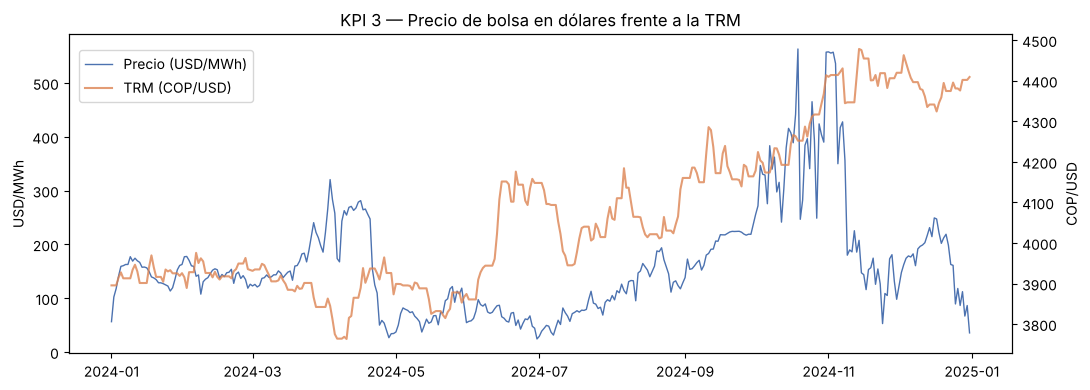

In [21]:
fig, ax1 = plt.subplots()
ax1.plot(kpi3_diario["fecha"], kpi3_diario["kpi3_precio_usd_mwh"], color="#4C72B0", lw=1, label="Precio (USD/MWh)")
ax1.set_ylabel("USD/MWh")
ax2 = ax1.twinx()
ax2.plot(kpi3_diario["fecha"], kpi3_diario["trm"], color="#DD8452", alpha=0.8, label="TRM (COP/USD)")
ax2.set_ylabel("COP/USD")
ax1.set_title("KPI 3 — Precio de bolsa en dólares frente a la TRM")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
plt.tight_layout()
plt.show()

### Lectura de los KPI en 2024

Con los resultados calculados arriba:

- **Pregunta 1 — embalses y precio.** Sobre todo el año la correlación es prácticamente nula (0,04), y el precio más alto no está en el nivel "Bajo" de embalse sino en el "Medio" (≈927 COP/kWh de promedio frente a ≈530 en "Bajo"). La razón es que la crisis de precios de octubre ocurrió con embalses en niveles intermedios, pero con aportes de agua muy bajos; en cambio, abril (nivel mínimo del año) tuvo precios altos pero no extremos. El KPI 1 muestra que la relación sí existe, pero por episodios: es fuertemente negativa en marzo (−0,86), septiembre (−0,95), noviembre (−0,89) y diciembre (−0,93), y se rompe en mayo y octubre. Conclusión para el observatorio: el **nivel** del embalse por sí solo no basta para anticipar el precio; importa más hacia dónde se está moviendo y cuánta agua está entrando. Esto justifica monitorear el indicador de forma continua y sugiere agregar los aportes hídricos de XM como variable en una siguiente versión.
- **Pregunta 2 — demanda por tipo de día.** Un fin de semana consume en promedio el 91,8 % de un día normal, y el valor es muy estable entre meses (entre 90,5 % y 92,8 %). Un festivo consume en promedio el 87,3 %, pero varía más (de 81,5 % en enero a 92 % en mayo): los festivos de comienzo y fin de año pesan más que los puentes de mitad de año. Febrero, abril y septiembre no tuvieron festivos en día hábil, por eso aparecen vacíos.
- **Pregunta 3 — precio, TRM e IPC.** La TRM subió cerca de 12 % en el año (de ≈3.920 a ≈4.385 COP/USD de promedio mensual), mientras el precio de bolsa cambió varias veces de nivel en cuestión de semanas. El precio en dólares sigue casi la misma trayectoria que el precio en pesos: en octubre el precio subió 86 % en pesos y 83 % en dólares, con una TRM que subió apenas 1,6 %. La correlación diaria precio–TRM (0,43) refleja que ambas series subieron en el segundo semestre, no que la tasa de cambio explique el precio. Con el IPC de energía la correlación mensual es negativa (−0,54): el IPC bajó todo el año mientras el precio de bolsa subía. Esto es coherente con que el costo de la bolsa llega a las tarifas de los hogares con rezago y amortiguado por los contratos de largo plazo, así que con 12 meses de datos no se observa el traslado.

## 10. Pipeline completo de preprocesamiento (para automatizar)

Todos los pasos anteriores se encadenan en una función. Recibe la base maestra cruda (la salida de la Entrega 2) y devuelve la base analítica y los KPI. Se puede llamar justo después de `construir_base_maestra()` en el batch diario.

In [22]:
def preprocesar(base_maestra, verbose=False):
    df = tipar_y_ajustar_unidades(base_maestra)
    df = tratar_duplicados(df, verbose=verbose)
    df = tratar_faltantes(df, verbose=verbose)
    df = corregir_errores(df, verbose=verbose)
    df = marcar_atipicos(df)
    df = categorizar(df)
    df = estandarizar(df)
    df = df[ORDEN_COLUMNAS]

    kpi1 = kpi_correlacion_embalse_precio(df)
    kpi3 = kpi_precio_usd(df)
    kpis = {
        "kpi1_diario": kpi1[0],
        "kpi1_mensual": kpi1[1],
        "kpi1_por_nivel": kpi1[2],
        "kpi2_demanda_relativa": kpi_demanda_relativa(df)[1],
        "kpi3_diario": kpi3[0],
        "kpi3_mensual": kpi3[1],
    }
    df.to_parquet(f"{RUTA_SALIDA}/base_analitica_energia_colombia.parquet", index=False)
    df.to_csv(f"{RUTA_SALIDA}/base_analitica_energia_colombia.csv", index=False)
    for nombre, tabla in kpis.items():
        tabla.to_csv(f"{RUTA_SALIDA}/{nombre}.csv")
    return df, kpis


base_final, kpis = preprocesar(cargar_base_maestra())
print("Base analítica:", base_final.shape)
print("Coincide con la construida paso a paso:", base_final.equals(base_analitica))
print("Archivos generados en", RUTA_SALIDA, ":")
print(sorted(os.listdir(RUTA_SALIDA)))

Base cargada desde GitHub: 366 filas, 7 columnas
Base analítica: (366, 23)
Coincide con la construida paso a paso: True
Archivos generados en datos_procesados :
['base_analitica_energia_colombia.csv', 'base_analitica_energia_colombia.parquet', 'kpi1_diario.csv', 'kpi1_mensual.csv', 'kpi1_por_nivel.csv', 'kpi2_demanda_relativa.csv', 'kpi3_diario.csv', 'kpi3_mensual.csv']


## 11. Limitaciones

- La TRM de los dos primeros días de enero se aproximó con el primer valor del rango; la corrección de raíz es extraer desde unos días antes y propagar por vigencia.
- La regla de salto aislado (3 veces la mediana de 7 días) se calibró con 2024. Un evento real muy abrupto de un solo día podría marcarse como error, así que conviene revisar manualmente cada caso que detecte antes de publicarlo.
- Los terciles de `nivel_embalse` son relativos al periodo. Con más historia conviene usar el porcentaje de la capacidad útil del SIN.
- El IPC usado es la división "Alojamiento, agua, electricidad, gas y otros combustibles" (no exclusiva de electricidad) y es mensual; con 12 datos, su relación con el precio de bolsa es solo exploratoria.